# Assignment 4

Hao YAN (hy2878)

Part 1 trains an energy-based model and a diffusion model on CIFAR-10 and saves both for the API.

Install these packages

```python
%pip install torch torchvision datasets matplotlib tqdm
```

In [1]:
#Applied GenAI
#Hao YAN hy2878

import sys
from pathlib import Path

import torch


for candidate in [Path.cwd(), Path.cwd().parent, Path.cwd().parent / "gentext-app"]:
    if (candidate / "pyproject.toml").is_file():
        PROJECT_DIR = candidate.resolve()
        break
else:
    raise RuntimeError("Run this notebook from the repository or its notebooks folder.")

# Make helper_lib importable from the notebook
sys.path.insert(0, str(PROJECT_DIR))

from helper_lib.model import get_model

## Part 1: CIFAR-10 Data

In [2]:
from torch import nn
import matplotlib.pyplot as plt

from helper_lib.data_loader import get_cifar10_loader
from helper_lib.generator import show_images

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


Training images: 50000
Image batch shape: torch.Size([128, 3, 32, 32])
Pixel range: -1.0 to 1.0


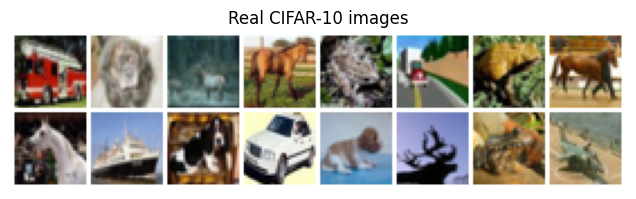

In [3]:
# CIFAR-10 from Hugging Face, the same copy used in Assignment 2
BATCH_SIZE = 128
train_loader = get_cifar10_loader(batch_size=BATCH_SIZE)

batch_images, batch_labels = next(iter(train_loader))

print("Training images:", len(train_loader.dataset))
print("Image batch shape:", batch_images.shape)
print("Pixel range:", batch_images.min().item(), "to", batch_images.max().item())

show_images((batch_images[:16] + 1) / 2, "Real CIFAR-10 images")

## Energy-Based Model

In [4]:
ebm = get_model("EBM")
print(ebm)

# Shape check, layer by layer
x = torch.rand(4, 3, 32, 32) * 2 - 1
with torch.no_grad():
    print(f"{'input':<12} {tuple(x.shape)}")
    for name, layer in ebm.layers.named_children():
        x = layer(x)
        print(f"{type(layer).__name__ + ' ' + name:<12} {tuple(x.shape)}")

assert x.shape == (4, 1)
print()
print("Shape check passed.")

EnergyModel(
  (layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (1): SiLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): SiLU()
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): SiLU()
    (6): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): SiLU()
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=512, out_features=128, bias=True)
    (10): SiLU()
    (11): Linear(in_features=128, out_features=1, bias=True)
  )
)
input        (4, 3, 32, 32)
Conv2d 0     (4, 32, 16, 16)
SiLU 1       (4, 32, 16, 16)
Conv2d 2     (4, 64, 8, 8)
SiLU 3       (4, 64, 8, 8)
Conv2d 4     (4, 128, 4, 4)
SiLU 5       (4, 128, 4, 4)
Conv2d 6     (4, 128, 2, 2)
SiLU 7       (4, 128, 2, 2)
Flatten 8    (4, 512)
Linear 9     (4, 128)
SiLU 10      (4, 128)
Linear 11    (4, 1)

Shape check passed.


In [5]:
from helper_lib.trainer import train_ebm
from helper_lib.generator import generate_ebm_images, langevin_sample

torch.manual_seed(42)
ebm = get_model("EBM").to(device)

# Same settings as the class practical
optimizer = torch.optim.Adam(ebm.parameters(), lr=0.0001, betas=(0.0, 0.999))

EBM_EPOCHS = 15

ebm, buffer = train_ebm(
    ebm,
    train_loader,
    optimizer,
    device=device,
    epochs=EBM_EPOCHS,
    alpha=0.1,
    steps=60,
    step_size=10.0,
    noise=0.005
)

print("Training finished.")

Epoch 1/15: 100%|██████████| 390/390 [00:59<00:00,  6.59it/s]


Loss: -0.0079 | Real energy: -0.0137 | Sample energy: -0.0030


Epoch 2/15: 100%|██████████| 390/390 [00:58<00:00,  6.71it/s]


Loss: 0.0002 | Real energy: -0.0039 | Sample energy: -0.0037


Epoch 3/15: 100%|██████████| 390/390 [00:58<00:00,  6.68it/s]


Loss: 0.0003 | Real energy: -0.0012 | Sample energy: -0.0014


... (20 outputs left out)

Epoch 14/15: 100%|██████████| 390/390 [00:57<00:00,  6.79it/s]


Loss: 0.0004 | Real energy: 0.0003 | Sample energy: -0.0001


Epoch 15/15: 100%|██████████| 390/390 [00:57<00:00,  6.81it/s]

Loss: 0.0004 | Real energy: 0.0000 | Sample energy: -0.0003
Training finished.


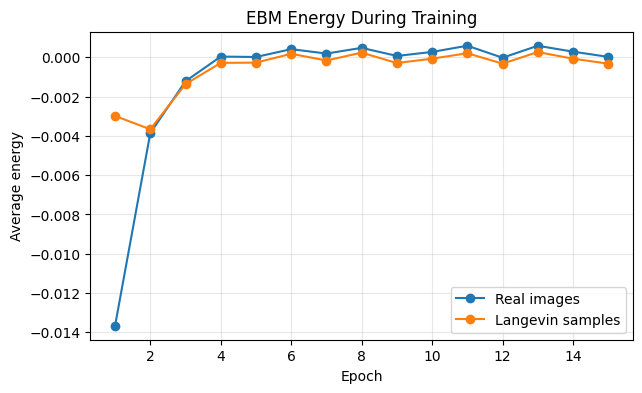

In [6]:
epochs = range(1, EBM_EPOCHS + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, ebm.history["real_energy"], marker="o", label="Real images")
plt.plot(epochs, ebm.history["fake_energy"], marker="o", label="Langevin samples")
plt.xlabel("Epoch")
plt.ylabel("Average energy")
plt.title("EBM Energy During Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

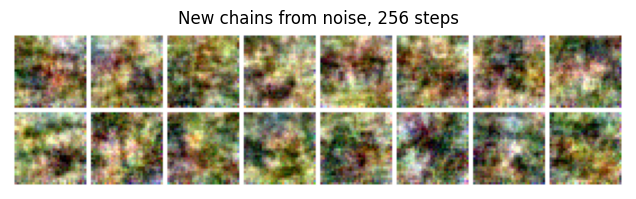

In [7]:
# New chains from uniform noise, as in the class practical
torch.manual_seed(42)
noise_images = torch.rand(16, 3, 32, 32, device=device) * 2 - 1
fresh_samples = langevin_sample(ebm, noise_images, steps=256, step_size=10.0, noise_std=0.01)
show_images((fresh_samples.cpu() + 1) / 2, "New chains from noise, 256 steps")

Chains started from noise stay close to noise after 256 steps, because the energy gradient with respect to the pixels is small. The chains in the replay buffer have been updated many times during training, so the API keeps some of them and continues them instead.

Saved chains: (2048, 3, 32, 32)


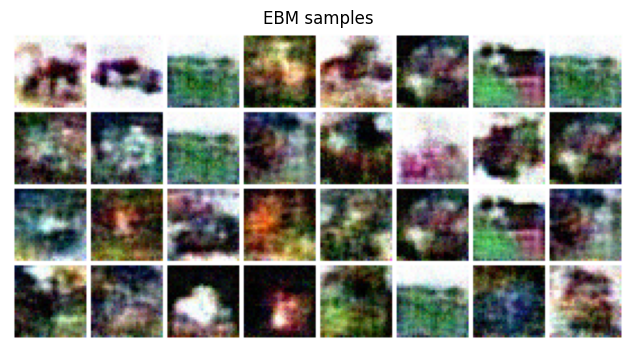

In [8]:
chains = buffer.select_chains(ebm)
print("Saved chains:", tuple(chains.shape))

# 60 more Langevin steps on randomly chosen chains, the same as the API default
ebm_samples = generate_ebm_images(ebm, chains, device, num_samples=32, steps=60, seed=42)
show_images(ebm_samples, "EBM samples")

In [9]:
MODEL_DIR = PROJECT_DIR / "app" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

EBM_PATH = MODEL_DIR / "cifar10_ebm.pth"

checkpoint = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in ebm.state_dict().items()
    },
    "image_size": [32, 32],
    "preprocessing": "ToTensor() + Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))",
    "chains": ((chains.cpu() + 1) * 127.5).round().to(torch.uint8),
    "epochs": EBM_EPOCHS,
    "langevin": {"steps": 60, "step_size": 10.0, "noise_std": 0.005}
}

torch.save(checkpoint, EBM_PATH)

print("Model saved to:", EBM_PATH.relative_to(PROJECT_DIR))
print(f"File size: {EBM_PATH.stat().st_size / 1024**2:.2f} MB")

Model saved to: app/models/cifar10_ebm.pth
File size: 7.18 MB


## Diffusion Model

In [10]:
diffusion = get_model("Diffusion")

num_params = sum(p.numel() for p in diffusion.network.parameters())
print(f"UNet parameters: {num_params:,}")

# The UNet predicts noise, so its output has the same shape as its input
x = torch.randn(4, 3, 32, 32)
noise_variances = torch.rand(4, 1, 1, 1)
with torch.no_grad():
    out = diffusion.network(x, noise_variances)

print("Input shape:", tuple(x.shape))
print("Output shape:", tuple(out.shape))
assert out.shape == x.shape
print("Shape check passed.")

UNet parameters: 1,950,627
Input shape: (4, 3, 32, 32)
Output shape: (4, 3, 32, 32)
Shape check passed.


In [11]:
from helper_lib.trainer import train_diffusion
from helper_lib.generator import generate_diffusion_images

torch.manual_seed(42)
diffusion = get_model("Diffusion").to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.AdamW(diffusion.network.parameters(), lr=0.001, weight_decay=0.0001)

DIFFUSION_EPOCHS = 30

diffusion = train_diffusion(
    diffusion,
    train_loader,
    criterion,
    optimizer,
    device=device,
    epochs=DIFFUSION_EPOCHS
)

print("Training finished.")

Epoch 1/30: 100%|██████████| 390/390 [01:04<00:00,  6.06it/s]


Loss: 0.1810


Epoch 2/30: 100%|██████████| 390/390 [01:03<00:00,  6.10it/s]


Loss: 0.1269


Epoch 3/30: 100%|██████████| 390/390 [01:01<00:00,  6.30it/s]


Loss: 0.1232


... (50 outputs left out)

Epoch 29/30: 100%|██████████| 390/390 [01:03<00:00,  6.14it/s]


Loss: 0.1155


Epoch 30/30: 100%|██████████| 390/390 [01:03<00:00,  6.15it/s]

Loss: 0.1151
Training finished.


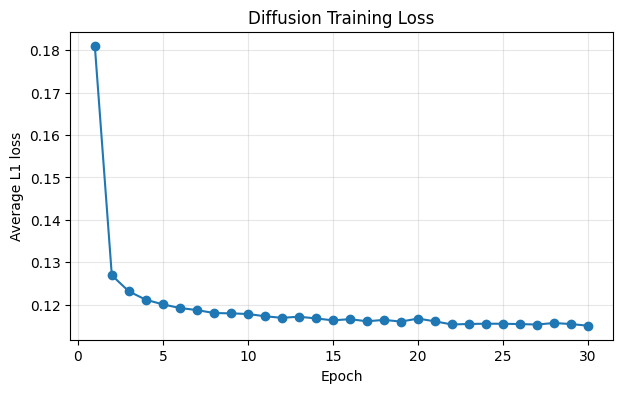

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, DIFFUSION_EPOCHS + 1), diffusion.history["loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average L1 loss")
plt.title("Diffusion Training Loss")
plt.grid(alpha=0.3)
plt.show()

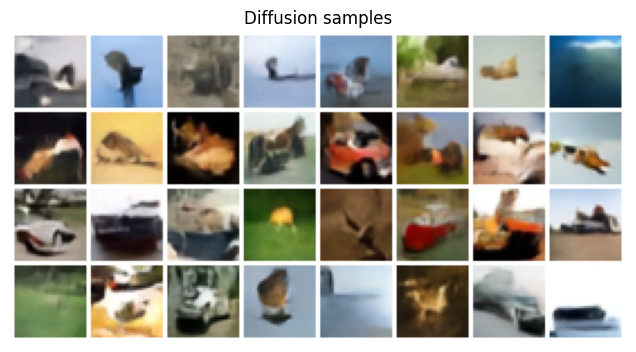

In [13]:
# 50 reverse diffusion steps with the EMA network, the same as the API default
diffusion_samples = generate_diffusion_images(diffusion, device, num_samples=32, steps=50, seed=42)
show_images(diffusion_samples, "Diffusion samples")

In [14]:
DIFFUSION_PATH = MODEL_DIR / "cifar10_diffusion.pth"

# The API samples with the EMA network only
checkpoint = {
    "ema_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in diffusion.ema_network.state_dict().items()
    },
    "image_size": [32, 32],
    "preprocessing": "ToTensor() + Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))",
    "schedule": "offset cosine, signal rate 0.95 to 0.02",
    "epochs": DIFFUSION_EPOCHS,
    "final_loss": diffusion.history["loss"][-1]
}

torch.save(checkpoint, DIFFUSION_PATH)

print("Model saved to:", DIFFUSION_PATH.relative_to(PROJECT_DIR))
print(f"File size: {DIFFUSION_PATH.stat().st_size / 1024**2:.2f} MB")

Model saved to: app/models/cifar10_diffusion.pth
File size: 7.47 MB
